# Stage 1: Unseen Dataset Evaluation, PI-HLNN (PL-MIND)

Loads the trained Stage 1 model (`stage1_pi_hlnn_best.pt`) and tests it on `unseen_dataset.csv`. The four scenarios come from a residential HDB flat and the SIT E2-L1 corridor and were not used for training or validation:

| Scenario | Type | d_direct | d_bounce | Samples |
|----------|------|----------|----------|---------|
| 4.55m | LOS | 4.55 m | - | 600 |
| 10.19m | LOS | 10.19 m | - | 600 |
| 8.91m | NLOS | 6.10 m | 8.91 m | 600 |
| 12.79m | NLOS | 8.82 m | 12.79 m | 600 |

2400 samples in total (1200 LOS, 1200 NLOS).

The model was trained with BCE plus the tau separation loss and gets the raw CIR only.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import torch.nn as nn
import torch.nn.functional as F
from sklearn.metrics import (
    confusion_matrix, ConfusionMatrixDisplay,
    classification_report, roc_curve, auc
)
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Device: {device}")

Device: cuda


In [2]:
_saved = torch.load("stage1_pi_hlnn_config.pt", map_location="cpu", weights_only=False)
CONFIG = _saved["config"]
print("CONFIG loaded from stage1_pi_hlnn_config.pt")
print(CONFIG)

torch.manual_seed(CONFIG["seed"])
np.random.seed(CONFIG["seed"])

CONFIG loaded from stage1_pi_hlnn_config.pt
{'pre_crop': 10, 'post_crop': 50, 'total_len': 60, 'search_start': 740, 'search_end': 810, 'hidden_size': 32, 'input_size': 1, 'dropout': 0.2, 'ode_unfolds': 6, 'batch_size': 64, 'max_epochs': 50, 'lr': 0.001, 'weight_decay': 0.0001, 'warmup_epochs': 3, 'patience': 10, 'grad_clip': 1.0, 'val_ratio': 0.15, 'test_ratio': 0.15, 'seed': 42}


## 1. Model Architecture
Same definition as in `stage1_pi_hlnn.ipynb`, needed to load the `.pt` weights. Both circuits start from zeros.

In [3]:
class PILiquidCell(nn.Module):
    """Liquid time-constant cell of PL-MIND, as in stage1_pi_hlnn.ipynb (Eqs. 2-5 of the paper)."""
    def __init__(self, input_size, hidden_size, ode_unfolds=6):
        super().__init__()
        self.hidden_size = hidden_size
        self.input_size  = input_size
        self.ode_unfolds = ode_unfolds

        # Per-neuron CIR dynamics
        self.signal_decay = nn.Parameter(torch.empty(hidden_size).uniform_(0.001, 1.0))   # lambda
        self.noise_floor  = nn.Parameter(torch.empty(hidden_size).uniform_(-0.2, 0.2))    # v0
        self.smoothing    = nn.Parameter(torch.empty(hidden_size).uniform_(0.4, 0.6))      # k

        # Signal strength S(t): weighted gated feedback between hidden units
        self.coupling_w        = nn.Parameter(torch.empty(hidden_size, hidden_size).uniform_(0.001, 1.0))  # w_j in S(t)
        self.signal_target     = nn.Parameter(torch.empty(hidden_size, hidden_size).uniform_(-0.2, 0.2))   # v_target
        self.activation_center = nn.Parameter(torch.empty(hidden_size, hidden_size).uniform_(0.3, 0.8))    # sigma_j gate centre
        self.activation_width  = nn.Parameter(torch.empty(hidden_size, hidden_size).uniform_(3, 8))        # sigma_j gate width

        # Input coupling: CIR sample x(t) -> hidden state, I(x(t))
        self.input_coupling_w = nn.Parameter(torch.empty(input_size, hidden_size).uniform_(0.001, 1.0))
        self.input_center     = nn.Parameter(torch.empty(input_size, hidden_size).uniform_(0.3, 0.8))
        self.input_width      = nn.Parameter(torch.empty(input_size, hidden_size).uniform_(3, 8))

    def forward(self, x_t, h_prev, dt=1.0):
        # Ensure positivity via softplus
        decay     = F.softplus(self.signal_decay)      # lambda > 0
        smoothing = F.softplus(self.smoothing)          # k > 0
        coupling  = F.softplus(self.coupling_w)         # w_j > 0
        input_w   = F.softplus(self.input_coupling_w)   # input coupling > 0

        # I(x(t)): how strongly each CIR sample drives the hidden state
        input_gate    = torch.sigmoid(self.input_width * (x_t.unsqueeze(-1) - self.input_center))
        input_current = (input_w * input_gate * x_t.unsqueeze(-1)).sum(dim=1)   # I(x(t))

        # Eq. 5: Euler sub-steps of the CIR ODE
        smoothing_t = smoothing / (dt / self.ode_unfolds)   # k scaled by sub-step size
        v = h_prev   # v(t): current CIR state

        for _ in range(self.ode_unfolds):
            # Signal strength gate: sigma_j(v) = sigmoid(activation_width * (v - activation_center))
            pattern_gate = torch.sigmoid(
                self.activation_width.unsqueeze(0) * (v.unsqueeze(2) - self.activation_center.unsqueeze(0))
            )
            # Eq. 2: signal strength S(t) = sum_j w_j * sigma_j(v)
            gated_coupling = coupling.unsqueeze(0) * pattern_gate

            # S(t) * v_target and S(t) terms
            coupling_num = (gated_coupling * self.signal_target.unsqueeze(0)).sum(dim=1)  # sum_j w_j * sigma_j * v_target
            coupling_den = gated_coupling.sum(dim=1)                                       # S(t) = sum_j w_j * sigma_j

            # Eq. 4, semi-implicit Euler: v_new = (k*v + lambda*v0 + S*v_target + I) / (k + lambda + S + eps)
            numerator   = smoothing_t * v + decay * self.noise_floor + coupling_num + input_current
            denominator = smoothing_t + decay + coupling_den + 1e-8
            v = numerator / denominator
            v = torch.clamp(v, -1.0, 1.0)

        # Eq. 3: adaptive time constant tau = k / (lambda + S(t))
        tau = smoothing / (decay + coupling_den + 1e-8)
        return v, tau

In [4]:
class DualCircuit_PI_HLNN(nn.Module):
    """
    Dual-circuit PI-HLNN encoder (PL-MIND in the paper).
    Both circuits start from h0 = zeros(32) and the readout averages the
    hidden states over time.
    """
    def __init__(self, input_size=CONFIG["input_size"],
                 hidden_size=CONFIG["hidden_size"],
                 dropout=CONFIG["dropout"],
                 ode_unfolds=CONFIG["ode_unfolds"]):
        super().__init__()
        self.hidden_size = hidden_size

        self.cell_los  = PILiquidCell(input_size, hidden_size, ode_unfolds)
        self.cell_nlos = PILiquidCell(input_size, hidden_size, ode_unfolds)

        self.P_nlos2los = nn.Linear(hidden_size, hidden_size, bias=False)
        self.P_los2nlos = nn.Linear(hidden_size, hidden_size, bias=False)

        self.gate_los  = nn.Linear(hidden_size * 2, hidden_size)
        self.gate_nlos = nn.Linear(hidden_size * 2, hidden_size)

        self.classifier = nn.Sequential(
            nn.Linear(hidden_size * 2, hidden_size),
            nn.SiLU(),
            nn.Dropout(dropout),
            nn.Linear(hidden_size, 1),
            nn.Sigmoid()
        )

    def _run_circuits(self, x_seq):
        batch_size, seq_len, _ = x_seq.size()

        h_los  = torch.zeros(batch_size, self.hidden_size, device=x_seq.device)
        h_nlos = torch.zeros(batch_size, self.hidden_size, device=x_seq.device)

        los_states, nlos_states = [], []
        tau_los_sum  = torch.zeros_like(h_los)
        tau_nlos_sum = torch.zeros_like(h_nlos)
        tau_los_hist_list, tau_nlos_hist_list = [], []

        for t in range(seq_len):
            x_t = x_seq[:, t, :]

            proj_nlos_to_los = self.P_nlos2los(h_nlos)
            proj_los_to_nlos = self.P_los2nlos(h_los)

            g_los  = torch.sigmoid(self.gate_los( torch.cat([h_los,  proj_nlos_to_los], dim=1)))
            g_nlos = torch.sigmoid(self.gate_nlos(torch.cat([h_nlos, proj_los_to_nlos], dim=1)))

            h_los_in  = h_los  + g_los  * proj_nlos_to_los
            h_nlos_in = h_nlos + g_nlos * proj_los_to_nlos

            h_los,  tau_los  = self.cell_los( x_t, h_los_in)
            h_nlos, tau_nlos = self.cell_nlos(x_t, h_nlos_in)

            los_states.append(h_los.unsqueeze(1))
            nlos_states.append(h_nlos.unsqueeze(1))
            tau_los_sum  += tau_los
            tau_nlos_sum += tau_nlos
            tau_los_hist_list.append(tau_los.unsqueeze(1))
            tau_nlos_hist_list.append(tau_nlos.unsqueeze(1))

        los_all  = torch.cat(los_states,  dim=1)
        nlos_all = torch.cat(nlos_states, dim=1)
        tau_los_mean  = tau_los_sum  / seq_len
        tau_nlos_mean = tau_nlos_sum / seq_len
        tau_los_hist  = torch.cat(tau_los_hist_list,  dim=1)
        tau_nlos_hist = torch.cat(tau_nlos_hist_list, dim=1)
        return los_all, nlos_all, tau_los_hist, tau_nlos_hist, tau_los_mean, tau_nlos_mean

    def _pool_and_fuse(self, los_all, nlos_all):
        """Average each circuit's hidden trajectory over time, (1/T) * sum_t h(t),
           and concatenate the two."""
        h_los_avg  = los_all.mean(dim=1)   # (batch, hidden)
        h_nlos_avg = nlos_all.mean(dim=1)  # (batch, hidden)
        return torch.cat([h_los_avg, h_nlos_avg], dim=1)   # (batch, 2*hidden)

    def forward(self, x_seq, return_dynamics=False):
        los_all, nlos_all, tau_los_hist, tau_nlos_hist, tau_los_mean, tau_nlos_mean = \
            self._run_circuits(x_seq)
        h_fused = self._pool_and_fuse(los_all, nlos_all)
        pred = self.classifier(h_fused)
        if return_dynamics:
            return pred, los_all, nlos_all, tau_los_hist, tau_nlos_hist, tau_los_mean, tau_nlos_mean
        return pred, tau_los_mean, tau_nlos_mean

    def embed(self, x_seq):
        """Return 64-dim fused embedding for Stage 2/3."""
        los_all, nlos_all, _, _, _, _ = self._run_circuits(x_seq)
        return self._pool_and_fuse(los_all, nlos_all)

## 2. Load Unseen Dataset
Same preprocessing as in training: RXPACC normalisation, leading-edge alignment, 60-sample crop and min-max scaling to [0, 1]. CIR only.

In [5]:
def get_roi_alignment(sig, search_start=CONFIG["search_start"],
                      search_end=CONFIG["search_end"]):
    region = sig[search_start:search_end]
    if len(region) == 0:
        return np.argmax(sig)
    peak_local = np.argmax(region)
    peak_idx = search_start + peak_local
    peak_val = sig[peak_idx]
    noise_section = sig[:search_start]
    if len(noise_section) > 10:
        noise_mean = np.mean(noise_section)
        noise_std = np.std(noise_section)
        threshold = max(noise_mean + 3 * noise_std, 0.05 * peak_val)
    else:
        threshold = 0.05 * peak_val
    leading_edge = peak_idx
    for i in range(peak_idx, max(search_start - 20, 0), -1):
        if sig[i] < threshold:
            leading_edge = i + 1
            break
    return leading_edge


def load_unseen_dataset(filepath):
    """Load and preprocess the unseen dataset (CIR only)."""
    PRE = CONFIG["pre_crop"]
    TOTAL = CONFIG["total_len"]

    df = pd.read_csv(filepath)
    print(f"Loaded {len(df)} rows from {filepath}")

    cir_cols = sorted(
        [c for c in df.columns if c.startswith("CIR")],
        key=lambda c: int(c.replace("CIR", ""))
    )

    X_list, y_list = [], []
    source_files = []
    skipped = 0

    for _, row in df.iterrows():
        sig = pd.to_numeric(row[cir_cols], errors='coerce').fillna(0).astype(float).values
        rxpacc_col = 'RXPACC' if 'RXPACC' in row.index else 'RX_PACC'
        rxpacc = float(row.get(rxpacc_col, 128.0))
        if rxpacc <= 0:
            skipped += 1
            continue
        sig = sig / rxpacc

        leading_edge = get_roi_alignment(sig)
        start = max(0, leading_edge - PRE)
        end = start + TOTAL
        if end > len(sig):
            end = len(sig)
            start = max(0, end - TOTAL)
        crop = sig[start:end]
        if len(crop) < TOTAL:
            crop = np.pad(crop, (0, TOTAL - len(crop)), mode='constant')
        local_min = np.min(crop)
        local_max = np.max(crop)
        rng = local_max - local_min
        if rng > 0:
            crop = (crop - local_min) / rng
        else:
            crop = np.zeros(TOTAL)

        X_list.append(crop)
        y_list.append(float(row["Label"]))
        source_files.append(row["Source_File"])

    if skipped:
        print(f"Skipped {skipped} rows (bad RXPACC)")

    X = np.array(X_list, dtype=np.float32).reshape(-1, TOTAL, 1)
    y = np.array(y_list, dtype=np.float32)

    print(f"Preprocessed: {len(y)} samples  |  LOS: {int((y==0).sum())}  |  NLOS: {int((y==1).sum())}")
    return X, y, source_files

In [6]:
X_unseen, y_unseen, sources = load_unseen_dataset(
    "../dataset/channels/unseen_dataset.csv"
)

Loaded 2400 rows from ../dataset/channels/unseen_dataset.csv


Preprocessed: 2400 samples  |  LOS: 1200  |  NLOS: 1200


## 3. Load Trained Model

In [7]:
model = DualCircuit_PI_HLNN().to(device)

state_dict = torch.load("stage1_pi_hlnn_best.pt", map_location=device, weights_only=True)
model.load_state_dict(state_dict)
model.eval()

total_params = sum(p.numel() for p in model.parameters())
print(f"Model loaded: DualCircuit_PI_HLNN")
print(f"  Total params: {total_params:,}")
print(f"  Hidden size: {model.hidden_size} per circuit")
print(f"  Embedding dim: {model.hidden_size * 2}")
print(f"  Training: BCE (hard targets) + tau separation (λ=0.1, margin=0.1)")

Model loaded: DualCircuit_PI_HLNN
  Total params: 16,897
  Hidden size: 32 per circuit
  Embedding dim: 64
  Training: BCE (hard targets) + tau separation (λ=0.1, margin=0.1)


## 4. Inference on Unseen Data

In [8]:
X_te = torch.tensor(X_unseen).to(device)
y_te = torch.tensor(y_unseen).unsqueeze(1).to(device)

with torch.no_grad():
    pred, tau_los_mean, tau_nlos_mean = model(X_te)

pred_binary = (pred > 0.5).float()
accuracy = (pred_binary == y_te).float().mean().item()

pred_np = pred.cpu().numpy().flatten()
pred_label_np = (pred_np > 0.5).astype(float)
true_np = y_unseen.flatten()

total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)

print(f"Unseen Dataset Accuracy: {100 * accuracy:.2f}%")
print(f"{'='*50}")
print(f"Parameters: {total_params:,} total | {trainable_params:,} trainable")
print(f"{'='*50}")
print(classification_report(true_np, pred_label_np, target_names=["LOS", "NLOS"]))

Unseen Dataset Accuracy: 97.17%
Parameters: 16,897 total | 16,897 trainable
              precision    recall  f1-score   support

         LOS       1.00      0.94      0.97      1200
        NLOS       0.95      1.00      0.97      1200

    accuracy                           0.97      2400
   macro avg       0.97      0.97      0.97      2400
weighted avg       0.97      0.97      0.97      2400



## 5. Per-Scenario Breakdown

In [9]:
sources_arr = np.array(sources)

scenario_names = np.array(["_".join(s.split("_")[:2]) for s in sources_arr])
unique_scenarios = sorted(set(scenario_names))

print(f"{'Scenario':<16} {'Type':<6} {'Samples':>7} {'Correct':>8} {'Accuracy':>9}")
print("-" * 52)

for scenario in unique_scenarios:
    mask = scenario_names == scenario
    s_true = true_np[mask]
    s_pred = pred_label_np[mask]
    s_correct = (s_true == s_pred).sum()
    s_total = len(s_true)
    s_acc = s_correct / s_total * 100
    s_type = "NLOS" if "nlos" in scenario else "LOS"
    print(f"{scenario:<16} {s_type:<6} {s_total:>7} {s_correct:>8} {s_acc:>8.2f}%")

print("-" * 52)
print(f"{'TOTAL':<16} {'':6} {len(true_np):>7} {int((true_np == pred_label_np).sum()):>8} {100*accuracy:>8.2f}%")

Scenario         Type   Samples  Correct  Accuracy
----------------------------------------------------
10.19m_los       LOS        600      536    89.33%
12.79m_nlos      NLOS       600      600   100.00%
4.55m_los        LOS        600      596    99.33%
8.91m_nlos       NLOS       600      600   100.00%
----------------------------------------------------
TOTAL                      2400     2332    97.17%


## 6. Confusion Matrix

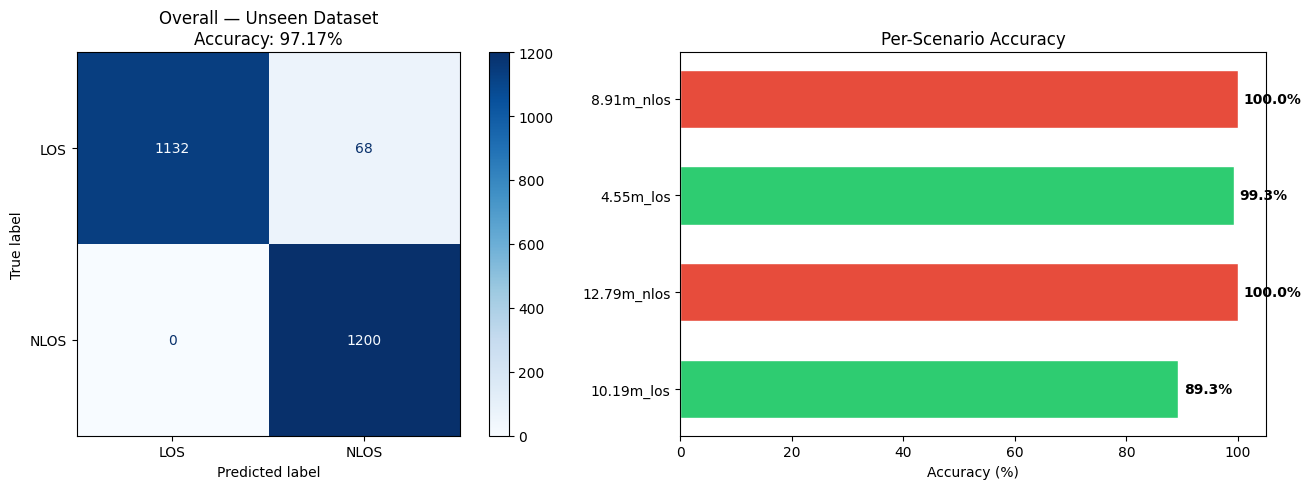

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Overall confusion matrix
cm = confusion_matrix(true_np, pred_label_np)
disp = ConfusionMatrixDisplay(cm, display_labels=["LOS", "NLOS"])
disp.plot(ax=axes[0], cmap="Blues", values_format="d")
axes[0].set_title(f"Overall — Unseen Dataset\nAccuracy: {100*accuracy:.2f}%")

# Per-scenario accuracy bar chart
scenario_labels, scenario_accs, scenario_colors = [], [], []
for scenario in unique_scenarios:
    mask = scenario_names == scenario
    s_acc = (true_np[mask] == pred_label_np[mask]).mean() * 100
    scenario_labels.append(scenario)
    scenario_accs.append(s_acc)
    scenario_colors.append("#2ecc71" if "los" in scenario and "nlos" not in scenario else "#e74c3c")

bars = axes[1].barh(scenario_labels, scenario_accs, color=scenario_colors, edgecolor="white", height=0.6)
axes[1].set_xlim(0, 105)
axes[1].set_xlabel("Accuracy (%)")
axes[1].set_title("Per-Scenario Accuracy")
for bar, acc in zip(bars, scenario_accs):
    axes[1].text(bar.get_width() + 1, bar.get_y() + bar.get_height()/2,
                 f"{acc:.1f}%", va="center", fontweight="bold")

plt.tight_layout()
plt.show()

## 7. ROC Curve

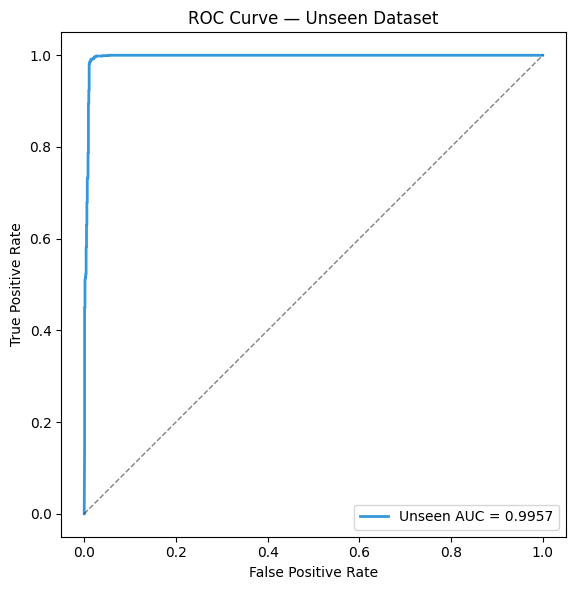

In [11]:
fpr, tpr, _ = roc_curve(true_np, pred_np)
roc_auc = auc(fpr, tpr)

fig, ax = plt.subplots(figsize=(6, 6))
ax.plot(fpr, tpr, color="#3498db", lw=2, label=f"Unseen AUC = {roc_auc:.4f}")
ax.plot([0, 1], [0, 1], "k--", lw=1, alpha=0.5)
ax.set_xlabel("False Positive Rate")
ax.set_ylabel("True Positive Rate")
ax.set_title("ROC Curve — Unseen Dataset")
ax.legend(loc="lower right")
ax.set_aspect("equal")
plt.tight_layout()
plt.show()

## 8. Confusion Matrix and Embedding

The 64-dim embedding (two circuits of 32) is projected to 2D with PCA. Each point is coloured by its confusion-matrix category (TN, TP, FP, FN).

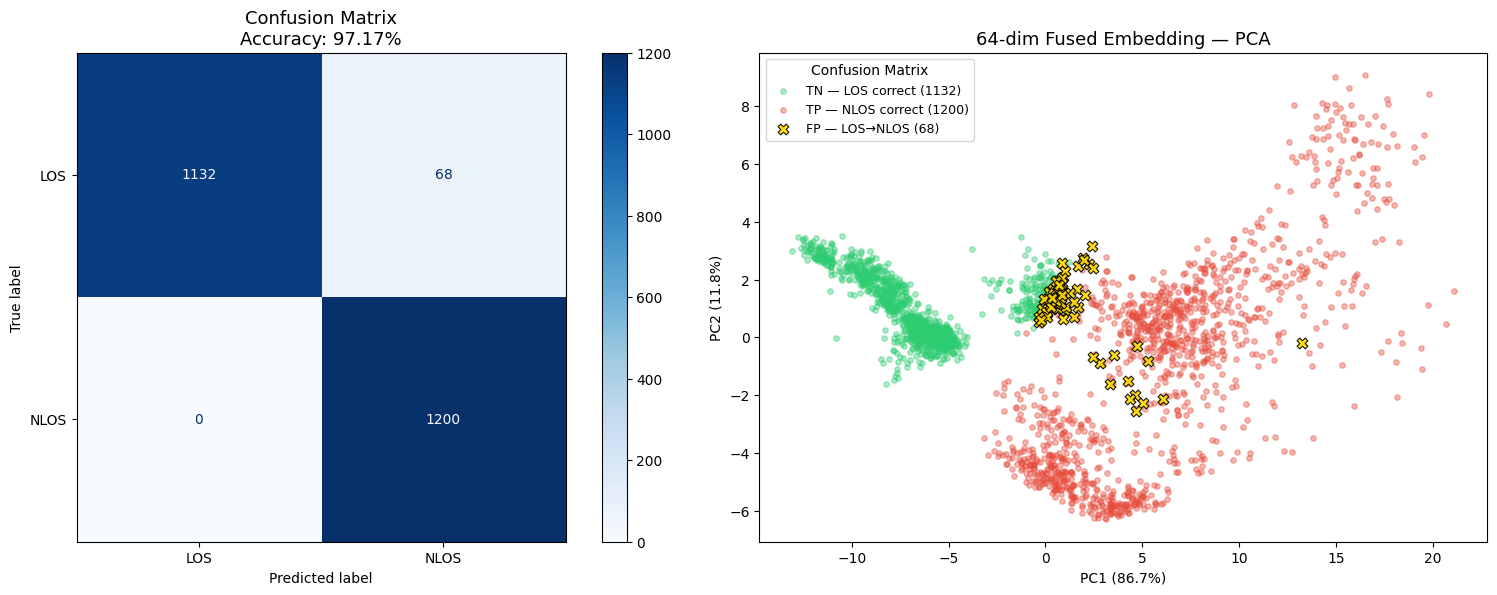

TN: 1132 | FP: 68 | TP: 1200 | FN: 0 | Total: 2400


In [12]:
los_mask = true_np == 0
nlos_mask = true_np == 1

with torch.no_grad():
    embeddings = model.embed(X_te).cpu().numpy()

scaler = StandardScaler()
emb_scaled = scaler.fit_transform(embeddings)
pca = PCA(n_components=2)
emb_2d = pca.fit_transform(emb_scaled)

# Confusion matrix categories
misclassified = true_np != pred_label_np
los_correct = los_mask & ~misclassified    # TN
los_wrong = los_mask & misclassified       # FP
nlos_correct = nlos_mask & ~misclassified  # TP
nlos_wrong = nlos_mask & misclassified     # FN

tn = int(los_correct.sum())
fp = int(los_wrong.sum())
tp = int(nlos_correct.sum())
fn = int(nlos_wrong.sum())

# Side-by-side: Confusion Matrix + PCA Embedding
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Left: Confusion Matrix
cm = confusion_matrix(true_np, pred_label_np)
disp = ConfusionMatrixDisplay(cm, display_labels=["LOS", "NLOS"])
disp.plot(ax=axes[0], cmap="Blues", values_format="d")
axes[0].set_title(f"Confusion Matrix\nAccuracy: {100*accuracy:.2f}%", fontsize=13)

# Right: PCA scatter
ax = axes[1]

ax.scatter(emb_2d[los_correct, 0], emb_2d[los_correct, 1],
           c="#2ecc71", alpha=0.4, s=15,
           label=f"TN \u2014 LOS correct ({tn})", zorder=3)
ax.scatter(emb_2d[nlos_correct, 0], emb_2d[nlos_correct, 1],
           c="#e74c3c", alpha=0.4, s=15,
           label=f"TP \u2014 NLOS correct ({tp})", zorder=3)
if fp > 0:
    ax.scatter(emb_2d[los_wrong, 0], emb_2d[los_wrong, 1],
               c="gold", marker='X', s=60, edgecolors='black', linewidths=0.8,
               alpha=0.9, label=f"FP \u2014 LOS\u2192NLOS ({fp})", zorder=7)
if fn > 0:
    ax.scatter(emb_2d[nlos_wrong, 0], emb_2d[nlos_wrong, 1],
               c="darkorange", marker='X', s=60, edgecolors='black', linewidths=0.8,
               alpha=0.9, label=f"FN \u2014 NLOS\u2192LOS ({fn})", zorder=7)

ax.set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]*100:.1f}%)")
ax.set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]*100:.1f}%)")
ax.set_title("64-dim Fused Embedding — PCA", fontsize=13)
ax.legend(loc="upper left", fontsize=9, title="Confusion Matrix", title_fontsize=10)

plt.tight_layout()
plt.show()

print(f"TN: {tn} | FP: {fp} | TP: {tp} | FN: {fn} | Total: {tn+fp+tp+fn}")

## 9. Prediction Confidence

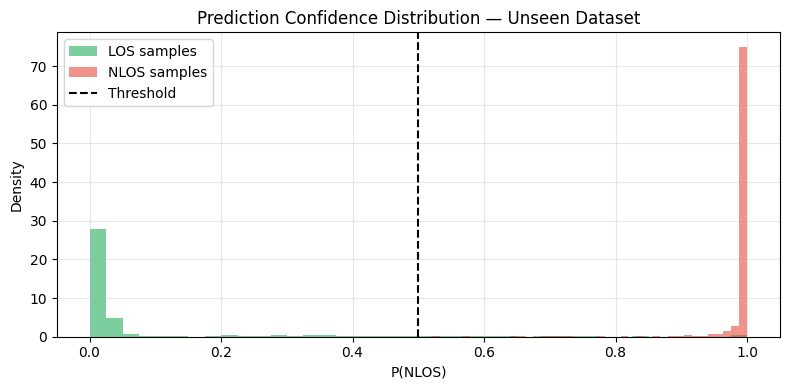

In [13]:
fig, ax = plt.subplots(figsize=(8, 4))

ax.hist(pred_np[true_np == 0], bins=40, alpha=0.6, color="#27ae60",
        label="LOS samples", density=True)
ax.hist(pred_np[true_np == 1], bins=40, alpha=0.6, color="#e74c3c",
        label="NLOS samples", density=True)
ax.axvline(0.5, color="black", ls="--", lw=1.5, label="Threshold")
ax.set_xlabel("P(NLOS)")
ax.set_ylabel("Density")
ax.set_title("Prediction Confidence Distribution — Unseen Dataset")
ax.legend()
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## 10. Tau Distribution (LOS vs NLOS Circuits)

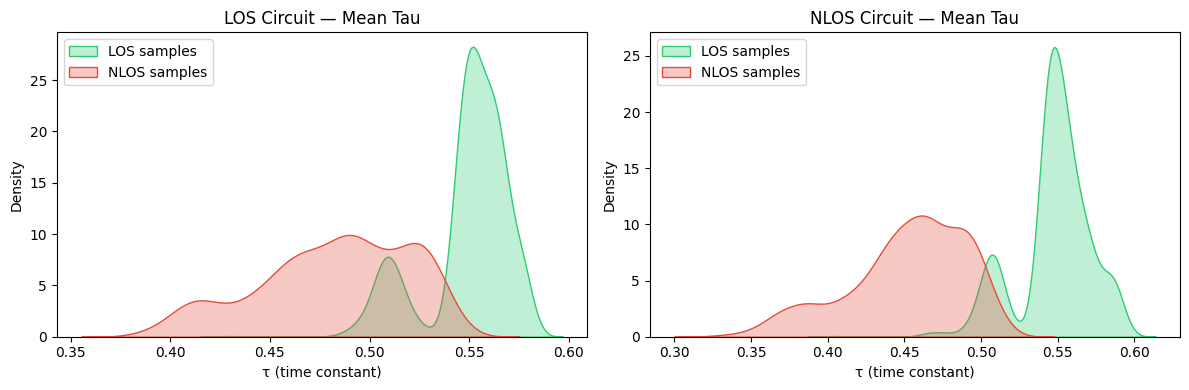

In [14]:
with torch.no_grad():
    _, _, _, tau_los_hist, tau_nlos_hist, _, _ = model(
        X_te, return_dynamics=True
    )
    tau_los_vals = tau_los_hist.mean(dim=(1, 2)).cpu().numpy()
    tau_nlos_vals = tau_nlos_hist.mean(dim=(1, 2)).cpu().numpy()

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# LOS circuit tau
sns.kdeplot(tau_los_vals[true_np == 0], ax=axes[0], color="#2ecc71",
            fill=True, alpha=0.3, label="LOS samples")
sns.kdeplot(tau_los_vals[true_np == 1], ax=axes[0], color="#e74c3c",
            fill=True, alpha=0.3, label="NLOS samples")
axes[0].set_title("LOS Circuit \u2014 Mean Tau")
axes[0].set_xlabel("\u03c4 (time constant)")
axes[0].legend()

# NLOS circuit tau
sns.kdeplot(tau_nlos_vals[true_np == 0], ax=axes[1], color="#2ecc71",
            fill=True, alpha=0.3, label="LOS samples")
sns.kdeplot(tau_nlos_vals[true_np == 1], ax=axes[1], color="#e74c3c",
            fill=True, alpha=0.3, label="NLOS samples")
axes[1].set_title("NLOS Circuit \u2014 Mean Tau")
axes[1].set_xlabel("\u03c4 (time constant)")
axes[1].legend()

plt.tight_layout()
plt.show()

## 11. Misclassified Samples

In [15]:
misclassified = true_np != pred_label_np
n_wrong = misclassified.sum()

if n_wrong == 0:
    print("No misclassified samples — perfect accuracy on unseen data!")
else:
    print(f"Misclassified: {n_wrong} / {len(true_np)} ({100*n_wrong/len(true_np):.2f}%)")
    print(f"\n{'Source File':<28} {'True':>6} {'Pred':>6} {'P(NLOS)':>9}")
    print("-" * 55)

    mis_idx = np.where(misclassified)[0]
    for i in mis_idx[:30]:
        lbl = "NLOS" if true_np[i] == 1 else "LOS"
        plb = "NLOS" if pred_label_np[i] == 1 else "LOS"
        print(f"{sources[i]:<28} {lbl:>6} {plb:>6} {pred_np[i]:>9.4f}")

    if len(mis_idx) > 30:
        print(f"... and {len(mis_idx) - 30} more")

    # Per-scenario misclassification breakdown
    print(f"\n{'Scenario':<16} {'Errors':>7} {'Total':>7} {'Error Rate':>11}")
    print("-" * 45)
    for scenario in unique_scenarios:
        mask = scenario_names == scenario
        errs = (true_np[mask] != pred_label_np[mask]).sum()
        total = mask.sum()
        if errs > 0:
            print(f"{scenario:<16} {errs:>7} {total:>7} {100*errs/total:>10.2f}%")

Misclassified: 68 / 2400 (2.83%)

Source File                    True   Pred   P(NLOS)
-------------------------------------------------------
10.19m_los_c5.csv               LOS   NLOS    0.5011
10.19m_los_c5.csv               LOS   NLOS    0.9982
10.19m_los_c5.csv               LOS   NLOS    0.5231
10.19m_los_c5.csv               LOS   NLOS    0.9999
10.19m_los_c5.csv               LOS   NLOS    0.9999
10.19m_los_c5.csv               LOS   NLOS    0.7231
10.19m_los_c5.csv               LOS   NLOS    0.5493
10.19m_los_c5.csv               LOS   NLOS    0.5384
10.19m_los_c5.csv               LOS   NLOS    0.7633
10.19m_los_c5.csv               LOS   NLOS    0.5223
10.19m_los_c5.csv               LOS   NLOS    0.7267
10.19m_los_c5.csv               LOS   NLOS    0.6188
10.19m_los_c5.csv               LOS   NLOS    0.5108
10.19m_los_c5.csv               LOS   NLOS    0.5843
10.19m_los_c5.csv               LOS   NLOS    0.9999
10.19m_los_c5.csv               LOS   NLOS    0.5444
10.19m_lo